# Derivatives and batching

Compute a scalar posterior's **21 latent-coordinate derivatives** for a
classic Caustics image. Compare every component to ordinary native
autograd before plotting or batching. Where two CUDA devices are
available, the source region is placed on the second GPU; CPU and
one-GPU execution use the same numerical example.

```{eval-rst}
:download:`Download notebook <derivatives.ipynb>`
```

The composition order is capture → target → derivative → batching.
Ordinary `.backward()` uses an AD-capable compiler; an explicit
derivative program can replay without accumulating an ordinary tape.

Run this notebook from the project root, or [download the example helpers](../_static/niagara-example-helpers.zip) and extract them beside a downloaded notebook. The helpers are examples, not part of the Niagara wheel.


In [1]:
import importlib.util
import json

import torch

import niagara as ng

missing = [
    name for name in ("caustics", "matplotlib", "numpy") if importlib.util.find_spec(name) is None
]
READY = not missing
if not READY:
    print("SKIPPED: install Niagara's full extra; missing", missing)
else:
    get_ipython().run_line_magic("matplotlib", "inline")
    import matplotlib.pyplot as plt
    import numpy as np

    from examples.niagara_examples.caustics import image_problem

    device = "cuda:0" if torch.cuda.is_available() else "cpu"
    source_device = "cuda:1" if torch.cuda.device_count() >= 2 else device
    print(
        json.dumps(
            {
                "niagara": ng.__version__,
                "torch": torch.__version__,
                "default": device,
                "source": source_device,
            },
            indent=2,
        )
    )

{
  "niagara": "0.7.0",
  "torch": "2.12.0+cu126",
  "default": "cuda:0",
  "source": "cuda:1"
}


## A target with nonzero sensitivities

The observation below is a noiseless reference image. The evaluation
point is near the latent prior median, which differs from the synthetic
truth. The scalar target includes a fixed illustrative noise variance
and standard-normal latent prior. These fixed choices make the synthetic comparison reproducible. No observed
lens system is being fitted.


In [2]:
if READY:
    native = image_problem(32, device=device)
    problem = image_problem(32, device=device)
    observed = native.model(native.truth).detach()
    variance = observed.abs() / 500 + 0.005**2
    z = torch.linspace(-0.05, 0.05, len(problem.names), device=device, dtype=torch.float64)

    def native_target(latent):
        residual = native.model(native.decode(latent)) - observed
        return -0.5 * (residual.square() / variance).sum() - 0.5 * latent.square().sum()

    q = z.detach().requires_grad_()
    native_value = native_target(q)
    native_gradient = torch.autograd.grad(native_value, q)[0].detach()

    placement = ng.assign_devices(
        problem.model,
        ng.DevicePlan(device, {"source": source_device} if source_device != device else {}),
    )
    render = ng.compile_model(problem.model, problem.decode(z), backend="eager")

    def target_transform(render_image):
        def target(latent):
            residual = render_image(problem.decode(latent)) - observed
            return -0.5 * (residual.square() / variance).sum() - 0.5 * latent.square().sum()

        return target

    target = render.transform(target_transform, z, backend="eager")
    derivative = target.transform(torch.func.grad_and_value, z, backend="auto")
    gradient, value = derivative(z)
    assert gradient.device == torch.device(device)
    assert problem.model.source.Re.device == torch.device(source_device)
    torch.testing.assert_close(gradient, native_gradient, atol=1e-8, rtol=1e-9)
    torch.testing.assert_close(value, native_value.detach(), atol=1e-8, rtol=1e-9)
    delta = (gradient - native_gradient).abs()
    print(
        json.dumps(
            {
                "parameters_checked": len(problem.names),
                "backend": derivative.backend,
                "value": value.item(),
                "gradient_device": str(gradient.device),
                "source_device": str(problem.model.source.Re.device),
                "gradient_abs_error_max": delta.max().item(),
                "reference_gradient_abs_max": native_gradient.abs().max().item(),
                "gradient_relative_l2": (delta.norm() / native_gradient.norm()).item(),
            },
            indent=2,
        )
    )

{
  "parameters_checked": 21,
  "backend": "cuda_graph",
  "value": -6556.398667633361,
  "gradient_device": "cuda:0",
  "source_device": "cuda:1",
  "gradient_abs_error_max": 7.275957614183426e-12,
  "reference_gradient_abs_max": 22027.220417553097,
  "gradient_relative_l2": 3.6660992525339023e-16
}


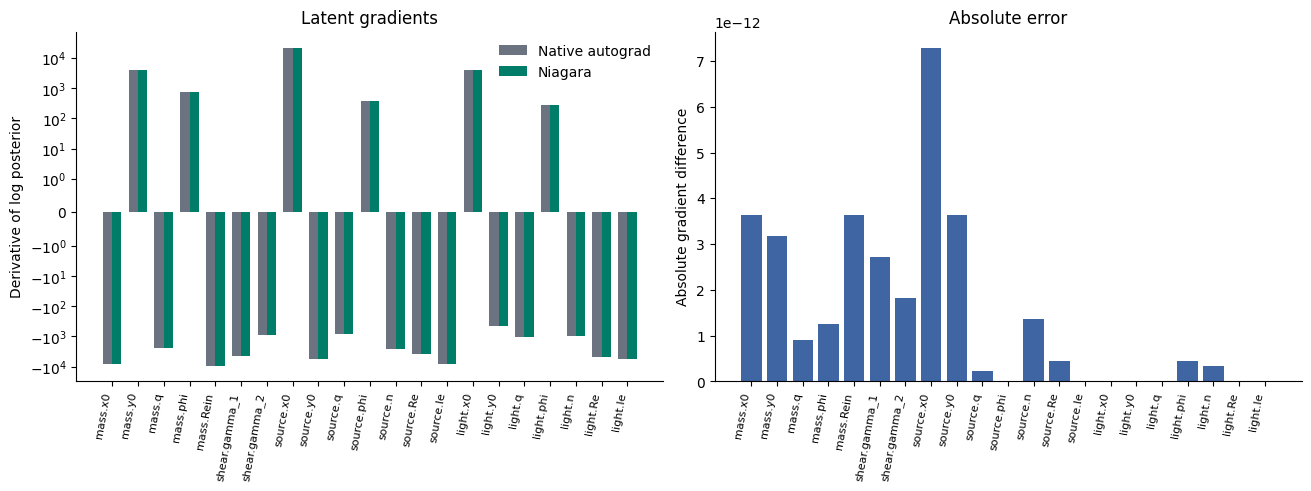

In [3]:
if READY:
    reference_values = native_gradient.cpu().numpy()
    actual_values = gradient.detach().cpu().numpy()
    positions = np.arange(len(problem.names))
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), layout="constrained")
    axes[0].bar(positions - 0.18, reference_values, 0.36, color="#6b7280", label="Native autograd")
    axes[0].bar(positions + 0.18, actual_values, 0.36, color="#007d68", label="Niagara")
    axes[0].set_yscale("symlog", linthresh=1)
    axes[0].set_title("Latent gradients")
    axes[0].set_ylabel("Derivative of log posterior")
    axes[0].legend(frameon=False)
    axes[1].bar(positions, np.abs(actual_values - reference_values), color="#3f65a3")
    axes[1].set_title("Absolute error")
    axes[1].set_ylabel("Absolute gradient difference")
    axes[1].ticklabel_format(axis="y", style="sci", scilimits=(0, 0))
    for ax in axes:
        ax.set_xticks(positions, problem.names, rotation=80, ha="right", fontsize=8)
        ax.spines[["top", "right"]].set_visible(False)
    plt.show()

The left panel preserves signs with a symmetric-log scale. The right
panel reports absolute error for every parameter; large pointwise
relative errors near a zero gradient need their reference magnitude for
interpretation. Parameter names come from the actual packed order.

## Batch the pure derivative

`ng.vmap` preserves region placement and evaluates the batch within
that layout; it does not shard the batch across GPUs. This small example
uses the captured eager tensor program to limit setup cost. Choose a
production compiler after defining the complete transformed program.


In [4]:
if READY:
    batch = torch.stack((z, z + 0.01))
    batched = ng.vmap(derivative, batch, backend="eager")
    gradients, values = batched(batch)
    for index, row in enumerate(batch):
        q = row.detach().requires_grad_()
        expected_value = native_target(q)
        expected_gradient = torch.autograd.grad(expected_value, q)[0]
        torch.testing.assert_close(gradients[index], expected_gradient, atol=1e-8, rtol=1e-9)
        torch.testing.assert_close(values[index], expected_value.detach(), atol=1e-8, rtol=1e-9)
    print("Batch gradients:", tuple(gradients.shape), "values:", values.detach().cpu().tolist())
    print("Output home:", gradients.device, "parameter components checked:", gradients.numel())
    placement.close()
    ng.assign_devices(problem.model, ng.DevicePlan(device)).close()

Batch gradients: (2, 21) values: [-6556.398667633361, -6856.327978354025]
Output home: cuda:0 parameter components checked: 42


## Supported composition

Apply surrounding losses and priors with `.transform()` before
batching. Use these APIs to compose transformations; an outer `torch.vmap` or FX
capture around a prepared callable is outside the supported interface. The default scalar reverse
path captures ordinary autograd into explicit outputs; `jacrev` and
`jacfwd` rely on native Torch support, whose cross-device combinations
may remain unsupported. The tested 2-D convolution lowering preserves
input, weight and bias gradients, including supported groups/stride.

Input metadata and known static state remain guarded. Different batch
shapes/layouts need matching programs. The final cleanup restores
native co-location. Discard prepared objects before changing their
placement. These comparisons check derivative accuracy; inference
convergence and performance require separate checks.
